# 6. A globe without a basemap

**Question:** Why can the shortest route look curved on a flat map?
**Objectives:** convert longitude/latitude to Cartesian vectors, construct a great-circle arc,
compute spherical distance, and hide the back hemisphere. **Time:** 40 minutes.

Two invented waypoints define an illustrative route on a sphere of radius 6,371 km. The sphere
approximates Earth; ellipsoidal geodesics are a different model. No coastline data or imagery
is used. Longitude and latitude are degrees on input; trigonometric functions require radians.
[Open in Lab](https://jltobias.github.io/JupyterLite-R/lite/lab/index.html?path=06-globes-and-great-circles.ipynb)

In [1]:
# Project: JupyterLite-R | Chapter 06 | Original spherical geometry.
# Author: project contributors with Codex | Contact: repository Issues.
# Created/updated: 2026-11-16 | Inputs: invented waypoints | Outputs: globe, route, distance.
# Dependencies: base R. Change log: initial lesson.
#' Convert degrees longitude/latitude to unit vectors, one point per row.
unit_xyz <- function(lon, lat) {
  lon <- lon * pi / 180; lat <- lat * pi / 180
  cbind(cos(lat) * cos(lon), cos(lat) * sin(lon), sin(lat))
}
a <- as.numeric(unit_xyz(-50, 20)); b <- as.numeric(unit_xyz(65, 45))
omega <- acos(max(-1, min(1, sum(a * b))))
stopifnot(omega > 1e-8, abs(pi - omega) > 1e-8) # Coincident/antipodal cases need explicit handling.
t <- seq(0, 1, length.out = 101)
route <- outer(sin((1-t) * omega) / sin(omega), a) + outer(sin(t * omega) / sin(omega), b)
stopifnot(max(abs(rowSums(route^2) - 1)) < 1e-10,
          max(abs(route[1, ] - a)) < 1e-10, max(abs(route[101, ] - b)) < 1e-10)
distance_km <- 6371 * omega
print(data.frame(central_angle_deg = omega * 180 / pi, spherical_distance_km = distance_km))

  central_angle_deg spherical_distance_km
1          92.23335              10255.88


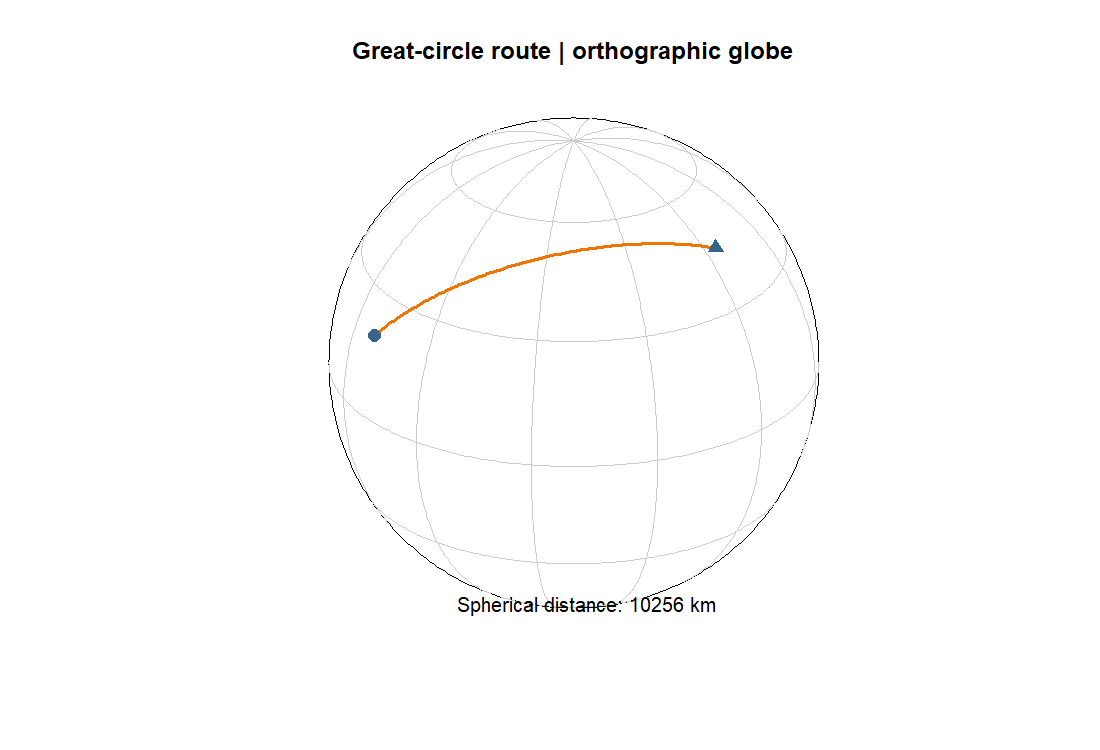

In [2]:
# Orthographic camera: look toward longitude 10 degrees, latitude 25 degrees.
lon0 <- 10 * pi / 180; lat0 <- 25 * pi / 180
east <- c(-sin(lon0), cos(lon0), 0)
north <- c(-sin(lat0)*cos(lon0), -sin(lat0)*sin(lon0), cos(lat0))
front <- c(cos(lat0)*cos(lon0), cos(lat0)*sin(lon0), sin(lat0))
#' Project visible unit vectors to an orthographic plane; back-side points become NA.
project <- function(xyz) {
  xy <- cbind(as.vector(xyz %*% east), as.vector(xyz %*% north))
  xy[as.vector(xyz %*% front) < 0, ] <- NA_real_
  xy
}
angle <- seq(0, 2*pi, length.out = 361)
plot(cos(angle), sin(angle), type = "l", asp = 1, axes = FALSE, xlab = "", ylab = "",
     main = "Great-circle route | orthographic globe")
for (lat in seq(-60, 60, 30)) lines(project(unit_xyz(seq(-180,180,1), lat)), col = "grey80")
for (lon in seq(-180, 150, 30)) lines(project(unit_xyz(lon, seq(-90,90,1))), col = "grey80")
lines(project(route), col = "darkorange2", lwd = 3)
points(project(rbind(a,b)), pch = c(16,17), col = "steelblue4", cex = 1.4)
legend("bottom", sprintf("Spherical distance: %.0f km", distance_km), bty = "n")

## Practice and check
1. Set both endpoints to the same point, then to antipodes. Why does the formula need guards?
2. Change only the camera. Confirm that the distance is unchanged.
3. Compare a quarter-equator arc: its length should be `pi * 6371 / 2` km.
**Checkpoint:** every route point has unit length, and the endpoints match exactly within tolerance.
The [interactive globe](https://jltobias.github.io/JupyterLite-R/gallery/#globe) shows this route
on a rotatable synthetic sphere. It provides geometry, not navigation advice.

## Sources
[R trigonometric functions](https://stat.ethz.ch/R-manual/R-devel/library/base/html/Trig.html);
[sf spherical geometry with s2](https://r-spatial.github.io/sf/articles/sf7.html).
The spherical interpolation implementation and graticule geometry here are original.